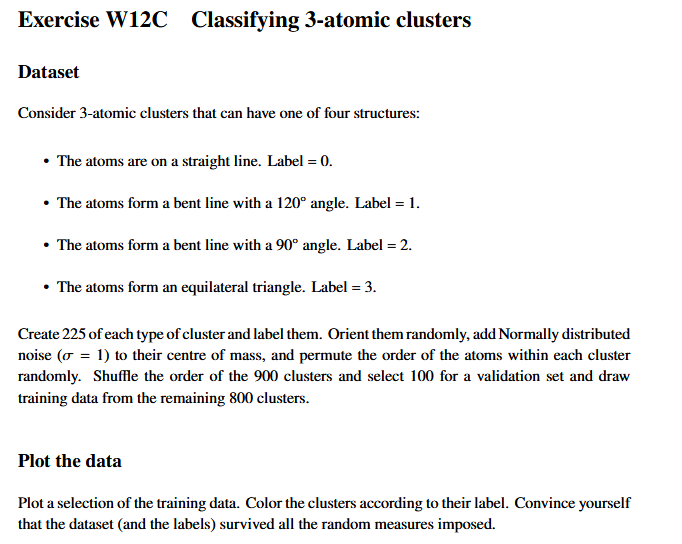

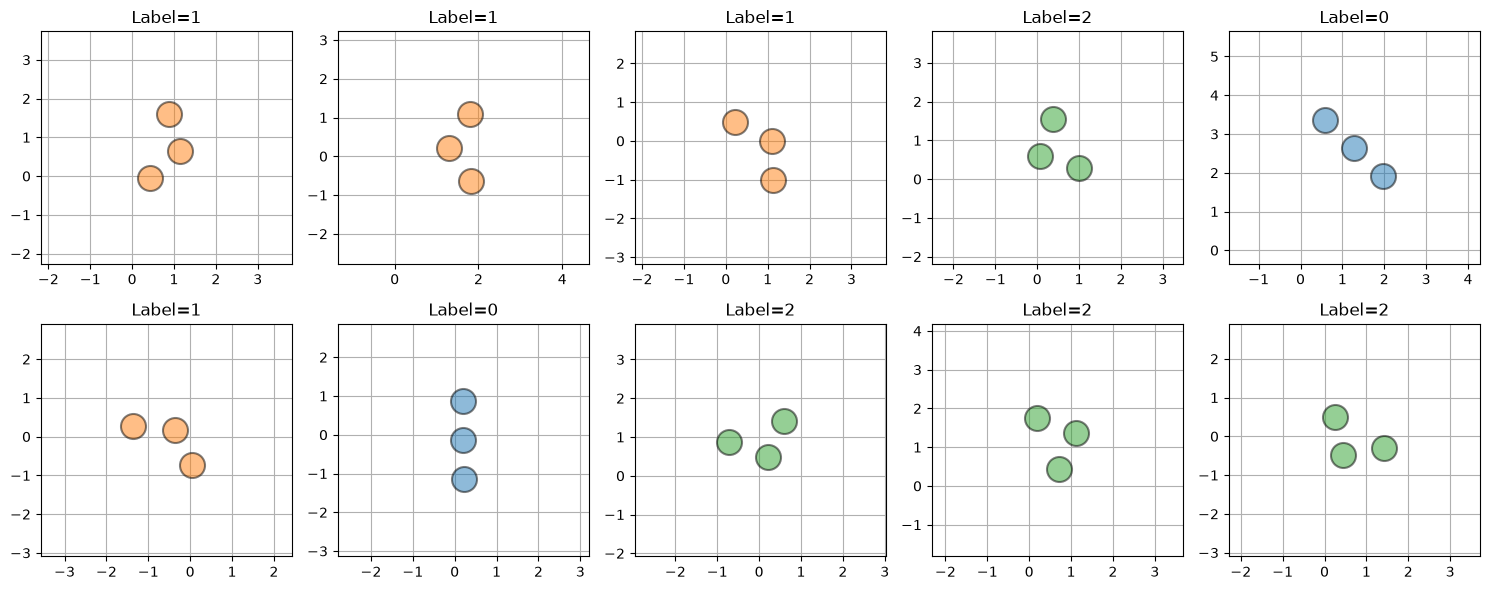

In [15]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def create_cluster(label):
    if label == 0:
        c = np.array([[-1.0, 0.0], [0.0, 0.0], [1.0, 0.0]])
    elif label == 1:
        c = np.array([[-1.0, 0.0], [0.0, 0.0], [0.5, np.sqrt(3)/2]])
    elif label == 2:
        c = np.array([[-1.0, 0.0], [0.0, 0.0], [0.0, 1.0]])
    elif label == 3:
        c = np.array([[-0.5, 0.0], [0.5, 0.0], [0.0, np.sqrt(3)/2]])
        
    c -= np.mean(c, axis=0)
    
    theta = np.random.uniform(0, 2 * np.pi)
    rot = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
    c = c @ rot.T
    
    c += np.random.normal(0, 1, 2)
    
    c = c[np.random.permutation(3)]
    
    return c.flatten()

X = []
y = []
for label in range(4):
    for _ in range(225):
        X.append(create_cluster(label))
        y.append(label)

X = np.array(X)
y = np.array(y)

shuffle_idx = np.random.permutation(900)
X = X[shuffle_idx]
y = y[shuffle_idx]

X_val = torch.tensor(X[:100], dtype=torch.float32)
y_val = torch.tensor(y[:100], dtype=torch.long)

X_train_pool = torch.tensor(X[100:], dtype=torch.float32)
y_train_pool = torch.tensor(y[100:], dtype=torch.long)

def plot_clusters_grid(data_tensor, label_tensor, preds_tensor=None, num_samples=10):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()
    
    for i in range(min(num_samples, len(data_tensor))):
        ax = axes[i]
        c = data_tensor[i].numpy().reshape(3, 2)
        true_lbl = label_tensor[i].item()
        
        display_color = plt.cm.tab10(preds_tensor[i].item()) if preds_tensor is not None else plt.cm.tab10(true_lbl)
        
        ax.plot(c[:, 0], c[:, 1], 'o', markersize=18, color=display_color, alpha=0.5, markeredgecolor='black', markeredgewidth=1.5)
        
        title_str = f"Label={true_lbl}"
        if preds_tensor is not None:
            title_str += f" | Pred={preds_tensor[i].item()}"
        ax.set_title(title_str)
        
        cx, cy = c[:, 0].mean(), c[:, 1].mean()
        ax.set_xlim(cx - 3, cx + 3)
        ax.set_ylim(cy - 3, cy + 3)
        ax.grid(True)
        
    plt.tight_layout()
    plt.show()

plot_clusters_grid(X_train_pool, y_train_pool)

The data preparation establishes 225 clusters for each of the four structures (straight, $120^\circ$, $90^\circ$, and equilateral), introducing random orientation and normally distributed center of mass noise ($\sigma=1$) to prevent the network from relying on absolute coordinates. By permuting the atomic order and applying shifts, the labels survive entirely on the intrinsic relative geometry of the 3-atom system.

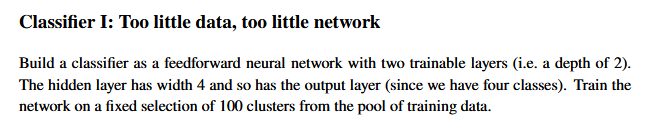
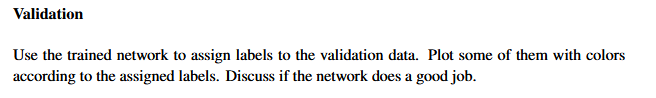

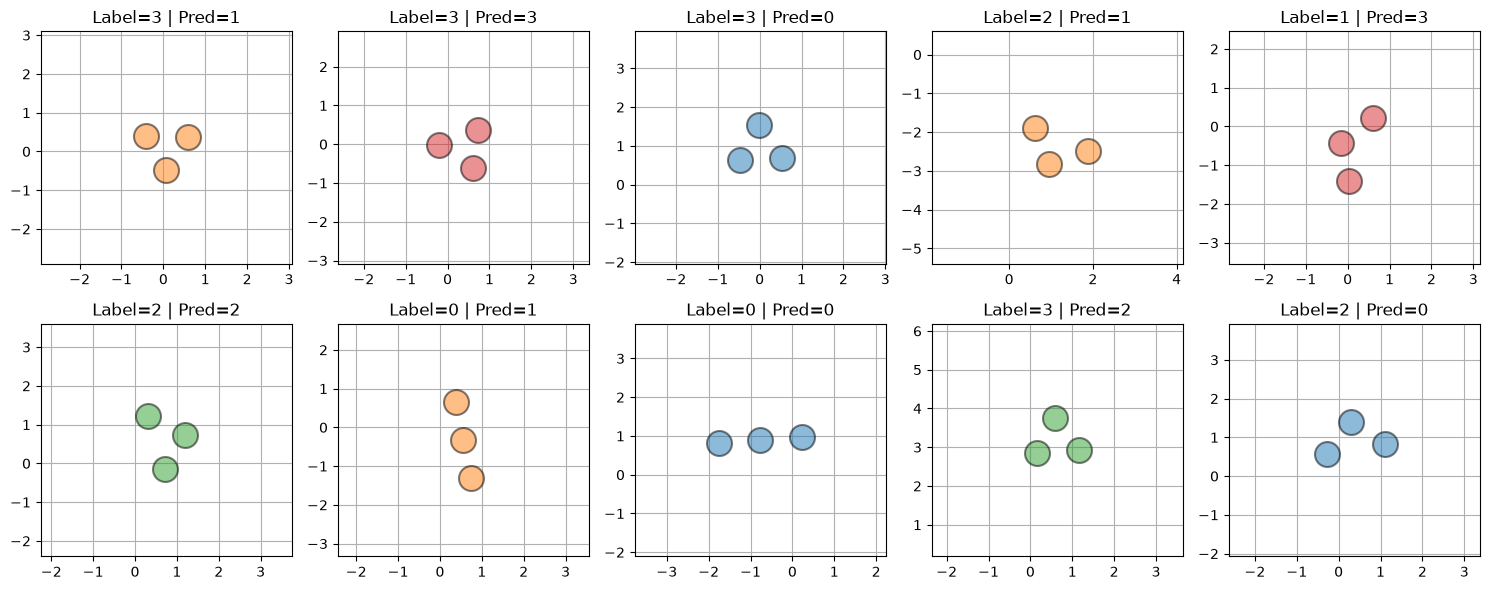

In [16]:
X_train_small = X_train_pool[:100]
y_train_small = y_train_pool[:100]

class ClassifierI(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(6, 4),
            nn.SiLU(),
            nn.Linear(4, 4)
        )
        
    def forward(self, x):
        return self.net(x)

model1 = ClassifierI()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model1.parameters(), lr=0.01)

for epoch in range(1500):
    model1.train()
    optimizer.zero_grad()
    loss = criterion(model1(X_train_small), y_train_small)
    loss.backward()
    optimizer.step()

model1.eval()
with torch.no_grad():
    train_preds_1 = torch.argmax(model1(X_train_small), dim=1)
    val_preds_1 = torch.argmax(model1(X_val), dim=1)

plot_clusters_grid(X_val, y_val, val_preds_1)

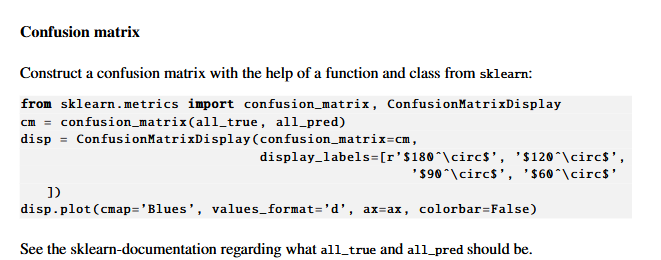

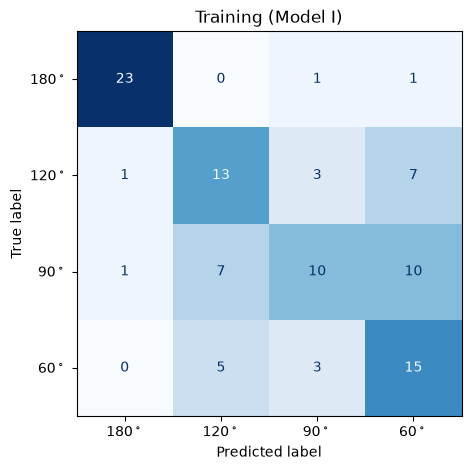

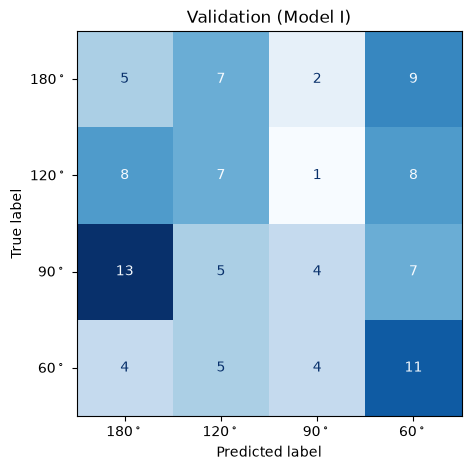

In [17]:
def plot_conf_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    display_labels = [r'$180^\circ$', r'$120^\circ$', r'$90^\circ$', r'$60^\circ$']
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
    
    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
    ax.set_title(title)
    plt.show()

plot_conf_matrix(y_train_small.numpy(), train_preds_1.numpy(), "Training (Model I)")
plot_conf_matrix(y_val.numpy(), val_preds_1.numpy(), "Validation (Model I)")

The first classifier relies on an extremely shallow network with a hidden layer width of 4 and is only provided with 100 training clusters. Because the network is too small and the data is too sparse, the network is unable to perform reliably, resulting in widely scattered, inaccurate predictions seen throughout the plotted validation clusters and a highly decentralized confusion matrix.


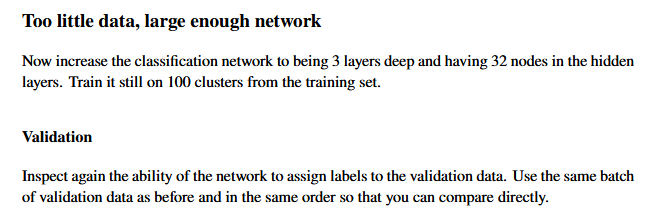
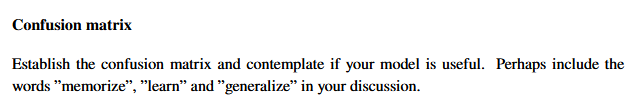

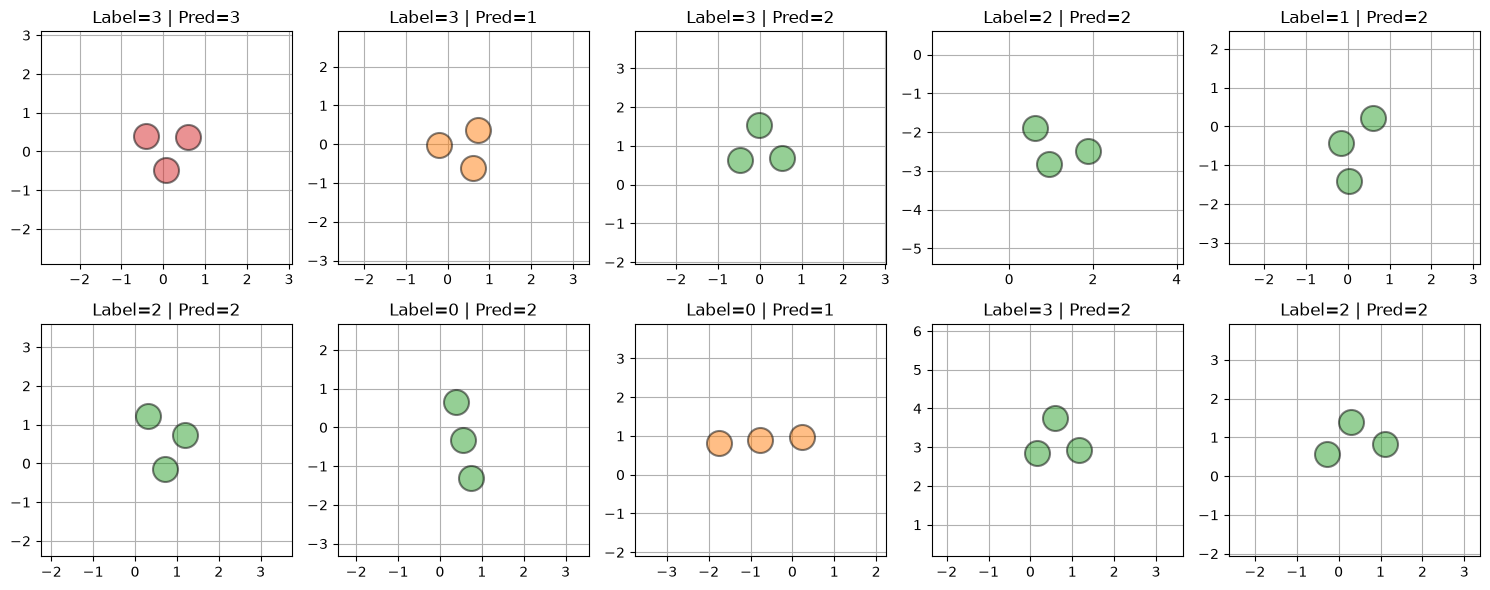

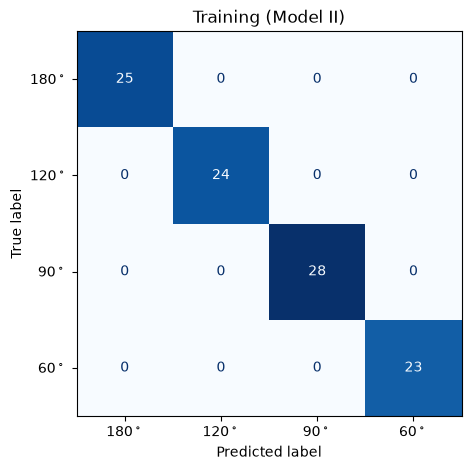

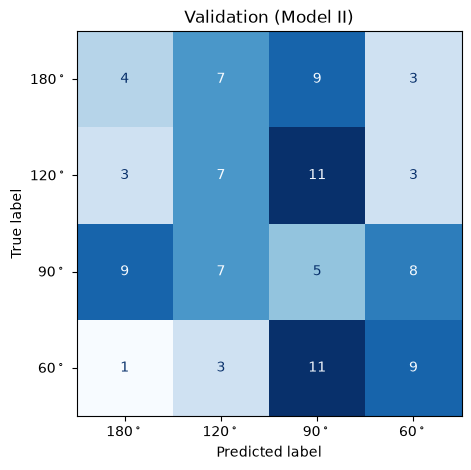

In [22]:
class ClassifierII(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(6, 32),
            nn.SiLU(),
            nn.Linear(32, 32),
            nn.SiLU(),
            nn.Linear(32, 4)
        )
        
    def forward(self, x):
        return self.net(x)

model2 = ClassifierII()
optimizer2 = optim.Adam(model2.parameters(), lr=0.01)

for epoch in range(2000):
    model2.train()
    optimizer2.zero_grad()
    loss = criterion(model2(X_train_small), y_train_small)
    loss.backward()
    optimizer2.step()

model2.eval()
with torch.no_grad():
    train_preds_2 = torch.argmax(model2(X_train_small), dim=1)
    val_preds_2 = torch.argmax(model2(X_val), dim=1)

plot_clusters_grid(X_val, y_val, val_preds_2)

plot_conf_matrix(y_train_small.numpy(), train_preds_2.numpy(), "Training (Model II)")
plot_conf_matrix(y_val.numpy(), val_preds_2.numpy(), "Validation (Model II)")

Increasing the network to 3 layers with 32 nodes provides the architecture with sufficient complexity to **memorize** the 100 training clusters flawlessly, represented by a perfectly diagonal training confusion matrix. However, because the network still lacks diverse data, it completely fails to **generalize** to unseen geometries, resulting in a validation matrix that resembles random guesswork. It is evident that the model did not truly **learn** the geometric rules defining the classes, but merely mapped specific noise coordinates to outputs.


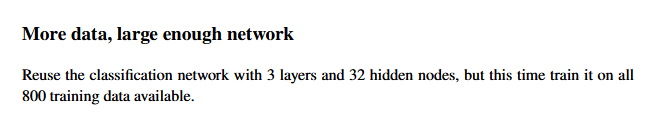

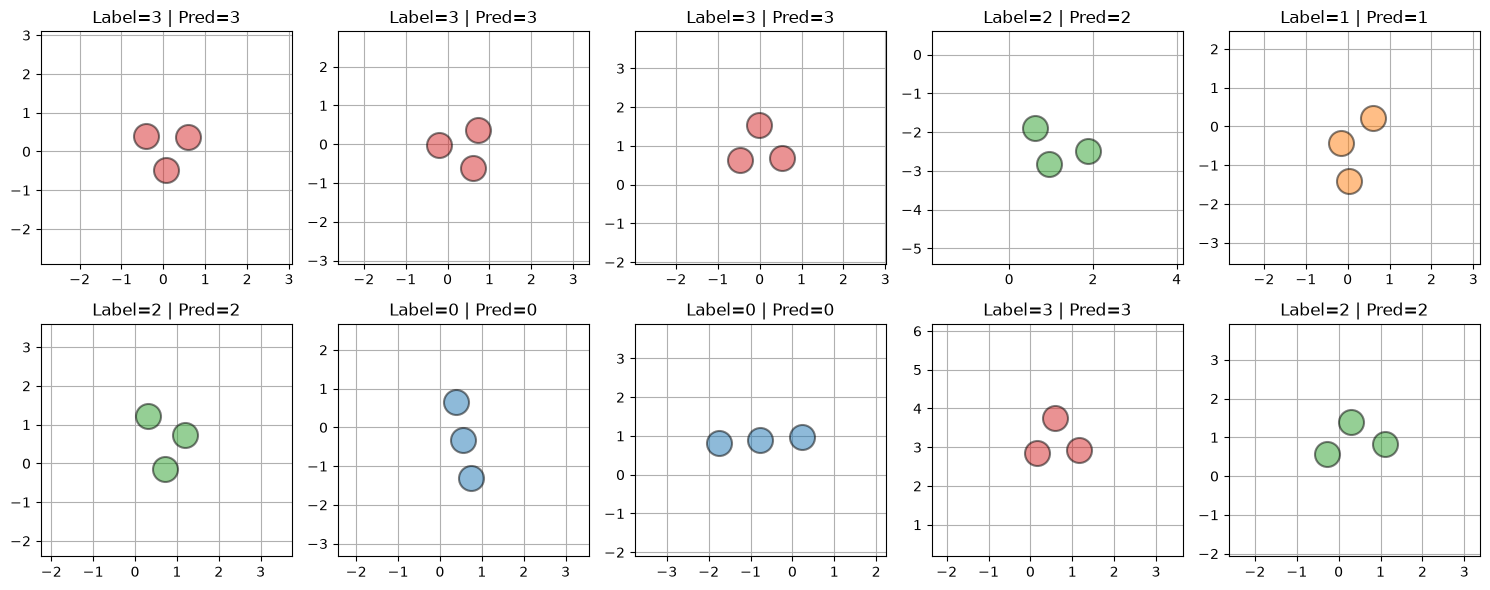

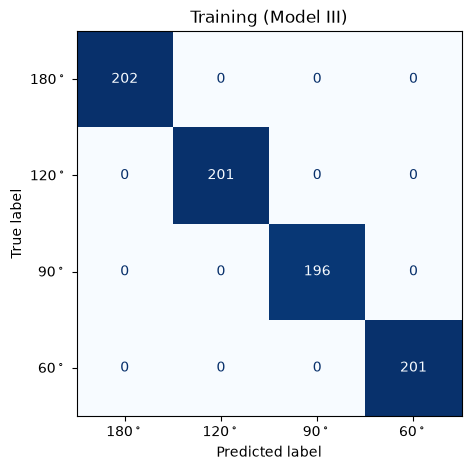

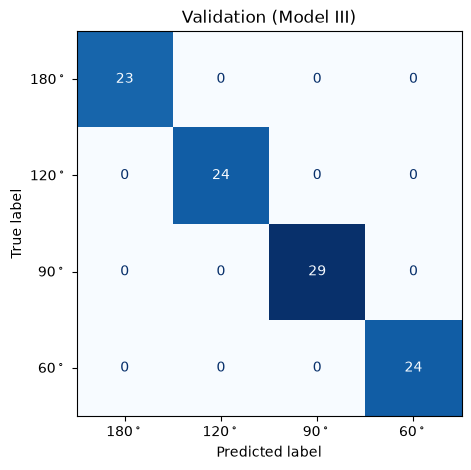

In [19]:
model3 = ClassifierII()
optimizer3 = optim.Adam(model3.parameters(), lr=0.01)

for epoch in range(2000):
    model3.train()
    optimizer3.zero_grad()
    loss = criterion(model3(X_train_pool), y_train_pool)
    loss.backward()
    optimizer3.step()

model3.eval()
with torch.no_grad():
    train_preds_3 = torch.argmax(model3(X_train_pool), dim=1)
    val_preds_3 = torch.argmax(model3(X_val), dim=1)

plot_clusters_grid(X_val, y_val, val_preds_3)
plot_conf_matrix(y_train_pool.numpy(), train_preds_3.numpy(), "Training (Model III)")
plot_conf_matrix(y_val.numpy(), val_preds_3.numpy(), "Validation (Model III)")

By providing the large capacity model with the entire set of 800 training clusters, the model successfully generalizes the geometric rules. It achieves near perfect categorization on both the training and validation sets, heavily populating only the true diagonal of the confusion matrices.


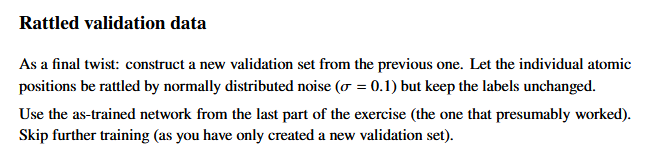

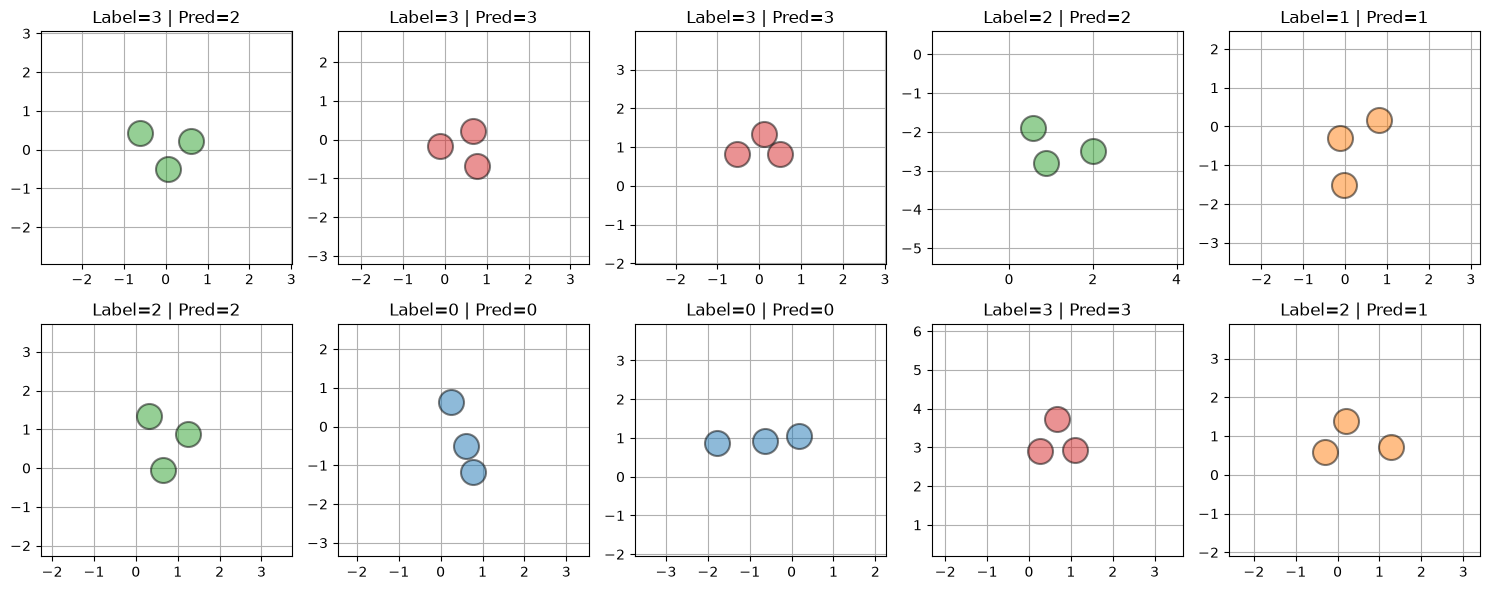

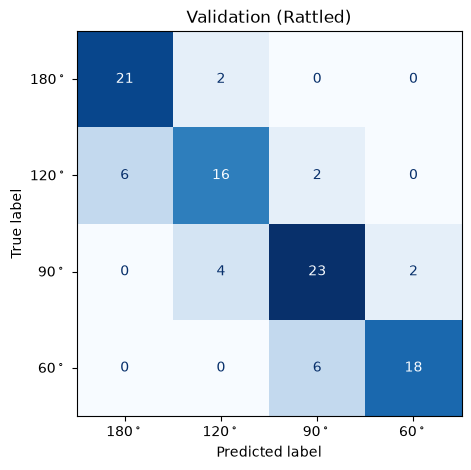

In [20]:
X_val_np = X_val.numpy().reshape(-1, 3, 2)
X_val_rattled = X_val_np + np.random.normal(0, 0.1, X_val_np.shape)
X_val_rattled = torch.tensor(X_val_rattled.reshape(-1, 6), dtype=torch.float32)

with torch.no_grad():
    val_preds_rattled = torch.argmax(model3(X_val_rattled), dim=1)

plot_clusters_grid(X_val_rattled, y_val, val_preds_rattled)
plot_conf_matrix(y_val.numpy(), val_preds_rattled.numpy(), "Validation (Rattled)")

Adding normally distributed noise ($\sigma=0.1$) to the specific atomic positions forces angles to physically shift from their ideal values. The resulting confusion matrix reveals an overlapping classification pattern where adjoining shapes bleed into one another. For instance, a $120^\circ$ line distorted by noise frequently resembles a $180^\circ$ or $90^\circ$ structure depending on the noise direction. Conversely, extreme configurations like the equilateral triangle ($60^\circ$) rarely deform enough to be confused with a straight line ($180^\circ$), keeping those specific matrix cells at zero.